# 13 · Isaac Sim 실습 — 물리 시뮬레이터에서 MPC 돌려 보기

> Isaac Sim은 01 노트의 "실제 카트" 역할을 한다. cuRobo의 MPPI가 모델로 계획하면 Isaac Sim이 물리 법칙대로 로봇을 움직이고, MPC는 그 결과를 다시 측정해서 계획을 고친다.

**지금 위치**

01~04 기초·MPC → 05~07 MPPI → 08~09 로봇팔 → 10~12 프로젝트 → **13 Isaac Sim 실습**

**이 노트를 끝내면**
1. Isaac Sim 스크립트가 어떤 순서로 만들어지는지(SimulationApp을 왜 먼저 만드는지) 설명할 수 있다.
2. 물리 dt, MPC dt, horizon이라는 세 가지 시간을 구분할 수 있다.
3. 실습 스크립트 `scripts/mpc_lab.py`로 η를 바꿔 실행하고, 12 노트의 지표로 결과를 해석할 수 있다.

**필요한 것:** [04](04_mpc.ipynb)의 MPC 루프, [06](06_mppi_obstacles.ipynb)의 η와 local minimum, [09](09_curobo_franka.ipynb)의 cuRobo solver, [12](12_results_analysis.ipynb)의 지표 · **예상 시간:** 40분 (직접 실행하면 실행마다 1분 정도 더)

## 복습 퀴즈 (12 노트)

<details><summary>1. 버퍼 포함 이격과 버퍼 제외 이격은 왜 정확히 20 mm 차이 나는가?</summary>

모든 충돌 구의 반지름에 똑같이 20 mm(buffer)를 더했기 때문이다. 같은 점·같은 구 집합에서 최솟값을 구하므로 최솟값도 정확히 20 mm 이동한다.
</details>

<details><summary>2. feasible이 True면 로봇이 손과 닿지 않았다고 말할 수 있나?</summary>

없다. feasible은 관절 한계 같은 기존 제약 검사 결과이고 손 비용은 들어가지 않는다. R은 손과 겹쳤는데도 100% feasible이었다.
</details>

<details><summary>3. 실제 Franka의 관절 각도가 위치 명령보다 늦게 따라간 정도는 최대 몇 도쯤이었나?</summary>

최대 약 3°. 빠르게 움직이는 구간에서 커지고 멈추면 0에 가까워진다.
</details>

In [1]:
import os, subprocess
import numpy as np
from common import *
from course import cart_step
plt = setup_plot()

STUDY = Path.cwd()
LAB = STUDY / 'scripts' / 'mpc_lab.py'            # 실습 스크립트
RESULTS = STUDY / 'scripts' / 'results'           # 실행 결과 (JSONL)
ISAAC = HOME / 'isaacsim'
print('실습 스크립트:', 'OK' if LAB.exists() else '없음', LAB)
print('저장된 결과  :', sorted(p.name for p in RESULTS.glob('*.jsonl')))

실습 스크립트: OK ~/isaacsim/study_franka_mppi/scripts/mpc_lab.py
저장된 결과  : ['eta0.025.jsonl', 'eta0.07.jsonl', 'no_obstacle.jsonl']


## 1. 왜 물리 시뮬레이터가 필요한가

### 문제
01~09 노트에서는 거의 모든 것이 모델 안에서 일어났다. 계획도 모델로 세우고, 계획을 실행한 결과도 같은 모델로 계산했다. 그런데 01 노트의 마찰 있는 카트에서 봤듯이, 실제 시스템은 모델과 다르게 움직인다. 실제 로봇팔에는 질량·관성·모터·관절 드라이브가 있다. 이런 차이 앞에서 MPC가 잘 동작하는지 어떻게 확인할까?

### 아이디어
실제 로봇 대신 **물리 시뮬레이터**에서 돌려 본다. Isaac Sim(NVIDIA)은 로봇의 질량·관성·관절 드라이브·접촉을 물리 엔진(PhysX)으로 계산하고 화면에 그려 준다. 역할을 01 노트와 맞춰 보면 다음과 같다.

| 01 노트 (1D 카트) | 이 노트 (Franka) | 하는 일 |
|---|---|---|
| `cart_step` (모델) | cuRobo의 rollout (가속도 적분 + FK) | 계획할 때 미래를 예측 |
| `real_cart_step` (마찰 있는 실제 카트) | Isaac Sim의 Franka (PhysX 물리 + 관절 드라이브) | 명령을 받아 실제로 움직임 |
| 매 스텝 실제 상태 다시 보기 (04 MPC) | 매 스텝 Isaac Sim에서 관절 상태 측정 | 모델과 실제의 차이를 보정 |

cuRobo의 모델에는 질량이 없다(09 노트). 그래서 Isaac Sim의 로봇은 항상 계획과 조금 다르게 움직이고, MPC가 이 차이를 매 스텝 보정한다.

## 2. 관절 드라이브 — 위치 명령을 주면 관절은 어떻게 따라가나

### 문제
MPC가 Isaac Sim에 보내는 것은 "이 관절을 이 각도로 보내라"는 **위치 명령**이다. 그런데 관절은 질량이 있어서 순간이동할 수 없다. 명령과 실제 각도는 어떤 관계일까?

### 아이디어
Isaac Sim의 관절 드라이브는 관절을 **용수철과 댐퍼**처럼 명령 각도로 끌어당긴다. 이것을 **PD 제어**(비례-미분 제어)라고 한다.

$$
\text{토크} = k_p\,(q_{\text{명령}} - q) - k_d\,\dot q
$$

말로 하면, 명령과 실제 각도의 차이에 비례해서 당기고(용수철 $k_p$), 움직이는 속도에 비례해서 브레이크를 건다(댐퍼 $k_d$). 그래서 실제 각도는 명령을 **조금 늦게** 따라간다. 12 노트에서 본 "명령 − 실제 최대 약 3°"가 이 지연이다.

아래는 질량 1인 관절 하나에 계속 앞서 나가는 명령을 주는 토이 예다(게인 값은 설명용).

**예측해 보기:** $k_p$를 키우면 실제 각도와 명령의 차이는 커질까, 작아질까?

kp=  100: 움직이는 동안 명령과의 최대 차이 0.191 rad
kp=  400: 움직이는 동안 명령과의 최대 차이 0.091 rad
kp= 1600: 움직이는 동안 명령과의 최대 차이 0.041 rad


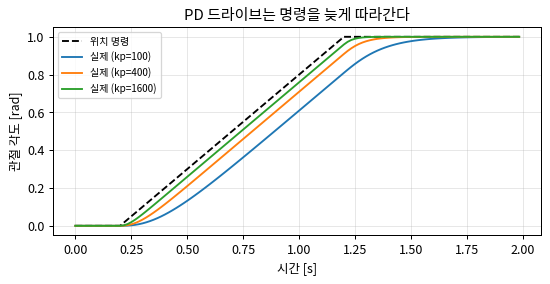

In [2]:
def pd_track(q_cmd, kp, kd, dt=1/60, sub=10):
    # 질량 1인 관절: 가속도 = kp (q_cmd - q) - kd v. 물리는 dt를 sub번 잘게 나눠 적분
    q, v, qs = 0.0, 0.0, []
    for qc in q_cmd:
        for _ in range(sub):
            a = kp * (qc - q) - kd * v
            q, v = cart_step(np.array([q, v]), a, dt / sub)
        qs.append(q)
    return np.array(qs)

t = np.arange(120) / 60                               # 2초
q_cmd = np.clip(t - 0.2, 0, 1.0)                      # 0.2초부터 1 rad/s로 1 rad까지 움직이는 명령
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, q_cmd, 'k--', label='위치 명령')
for kp in [100, 400, 1600]:
    q = pd_track(q_cmd, kp, 2 * np.sqrt(kp))          # kd는 진동하지 않는 값으로
    ax.plot(t, q, label=f'실제 (kp={kp})')
    print(f'kp={kp:5d}: 움직이는 동안 명령과의 최대 차이 {np.abs(q_cmd - q).max():.3f} rad')
ax.set(xlabel='시간 [s]', ylabel='관절 각도 [rad]', title='PD 드라이브는 명령을 늦게 따라간다'); ax.legend(fontsize=8)
plt.show()

**결과 해석:** $k_p$가 클수록 용수철이 단단해서 명령에 가깝게 따라가지만, 지연이 완전히 0이 되지는 않는다. 실제 Franka 실험의 드라이브 게인은 로그에 기록되어 있다.

In [3]:
cs = json.loads((EVIDENCE / 'HIGH' / 'control-settings.json').read_text())
print('실험의 관절 드라이브: kp = %.0f, kd = %.1f (7관절 같음)' % (cs['drive_stiffness'][0], cs['drive_damping'][0]))
print('명령 종류: 위치 목표만 (속도 목표 =', cs['drive_velocity_target'], ')')

실험의 관절 드라이브: kp = 35810, kd = 573.0 (7관절 같음)
명령 종류: 위치 목표만 (속도 목표 = zero )


**한 문장으로:** MPC가 매 스텝 계획을 처음부터 다시 세우는 이유를 "PD 드라이브의 지연"이라는 말을 넣어 설명해 보자.

## 3. 세 가지 시간 — 물리 dt, MPC dt, horizon

### 문제
Isaac Sim과 cuRobo는 각자 시간 간격을 갖고 있다. 둘이 어긋나면 어떻게 될까? 먼저 어떤 시간들이 있는지 정리해야 한다.

### 아이디어

| 이름 | 이 실습의 값 | 뜻 |
|---|---|---|
| **물리 dt** | 1/60 s | Isaac Sim이 `world.step()` 한 번에 진행하는 시간. 이 실습은 물리 한 스텝마다 MPC를 한 번 푼다 |
| **MPC dt** (`step_dt`) | 1/60 s | cuRobo 모델이 예측할 때 쓰는 기본 시간 간격. 물리 dt와 같게 맞췄다 |
| **horizon 길이** | 0.675 s | 30스텝 예측 구간 전체 길이. 앞 15스텝은 MPC dt, 뒤 15스텝은 0.04 s까지 점점 늘어난다(09 노트) |

MPC dt가 물리 dt와 다르면, 모델이 "한 스텝 뒤"라고 예측한 시점과 실제로 한 스텝 뒤의 시점이 달라진다. 프로젝트 초기 설정은 MPC dt 0.02 s, 물리 dt 1/60 s였고, 최종 실험에서 둘을 1/60 s로 맞췄다.

**예측해 보기:** MPC dt를 0.02 s로 바꾸면 horizon 길이는 몇 초가 될까? (09 노트의 `dt_array` 공식)

In [4]:
for base in [1 / 60, 0.02]:
    print(f'MPC dt = {base:.4f} s → horizon = {dt_array(base).sum():.3f} s')
f = RESULTS / 'eta0.025.jsonl'
if f.exists():
    st = json.loads(f.read_text().splitlines()[0])            # 첫 줄 = 실행 설정
    print('\n실습 실행 기록: horizon %.3f s, 후보 %d개 × %d스텝, MPPI 반복 %d회, β %.2f' % (
        st['horizon_s'], st['num_particles'], st['horizon'], st['n_iters'], st['beta']))

MPC dt = 0.0167 s → horizon = 0.675 s
MPC dt = 0.0200 s → horizon = 0.750 s

실습 실행 기록: horizon 0.675 s, 후보 400개 × 30스텝, MPPI 반복 5회, β 0.10


**결과 해석:** MPC dt를 0.02 s로 늘리면 horizon이 0.75 s로 길어진다. 같은 30스텝으로 더 먼 미래를 보지만, 모델의 한 스텝이 물리 한 스텝(1/60 s)과 맞지 않게 된다. 실습 기록의 0.675 s는 계산값과 같다.

## 4. Isaac Sim 스크립트의 구조 — SimulationApp을 먼저

### 문제
Isaac Sim의 로봇·장면 모듈(`isaacsim.core.api`, `omni.*`)을 그냥 import하면 오류가 난다. 왜 그럴까?

### 아이디어
Isaac Sim은 일반 파이썬 라이브러리가 아니다. 그 위에서 돌아가는 프로그램(Kit)을 먼저 띄워야 하고, Kit가 확장 모듈들을 불러온 뒤에야 `isaacsim.core.api` 같은 모듈을 import할 수 있다. 그래서 Isaac Sim 스크립트는 항상 다음 순서를 따른다.

```text
1. 인자 파싱
2. app = SimulationApp({...})      ← Kit 시작. 이게 먼저
3. from isaacsim.core.api import World ...   ← 그 다음에 Isaac 모듈 import
4. 장면 만들기 → 로봇 → cuRobo solver → 제어 루프
```

실습 스크립트의 첫 블록을 보자.

In [5]:
def show_section(path, start_marker, end_marker=None, width=120):
    # '# 1.' 같은 블록 표시 줄부터 다음 표시 줄 직전까지 출력
    lines = Path(path).read_text(encoding='utf-8').splitlines()
    s = next(i for i, l in enumerate(lines) if l.startswith(start_marker))
    e = next((i for i, l in enumerate(lines) if end_marker and l.startswith(end_marker)), len(lines))
    show_code(path, s + 1, e, width)

show_section(LAB, '# 1.', '# 2.')

   11| # 1. 인자 파싱 -> SimulationApp 생성 (omni/isaacsim 모듈은 반드시 이 뒤에 import)
   12| # ---------------------------------------------------------------------------
   13| import argparse
   14| import json
   15| import os
   16| import sys
   17| import tempfile
   18| import time
   19| from pathlib import Path
   20| 
   21| import numpy as np
   22| import torch
   23| 
   24| parser = argparse.ArgumentParser()
   25| parser.add_argument('--headless', action='store_true')
   26| parser.add_argument('--steps', type=int, default=600, help='physics steps (1/60 s each)')
   27| parser.add_argument('--eta', type=float, default=None, help='environment collision activation distance [m]; default 0.02 ...
   28| parser.add_argument('--buffer', type=float, default=0.02, help='collision_sphere_buffer [m] (hand_experiment uses 0.02)' ...
   29| parser.add_argument('--particles', type=int, default=None, help='MPPI num_particles (default 400)')
   30| parser.add_argument('--beta', type=float, default

**읽을 점**
- 39~41줄에서 `SimulationApp`을 만든 다음에야 43줄부터 Isaac 모듈을 import한다.
- `--eta`, `--buffer`, `--particles`, `--beta`가 이 실습에서 바꿔 볼 값들이다. 각각 06·08·07 노트에서 배운 장애물 비용 활성 거리, 충돌 구 여유, 후보 수, 온도다.
- 목표 A, B와 도달 기준(10 mm, 0.05 rad)은 프로젝트 실험과 같다.

## 5. 장면과 충돌 세계는 따로 만든다

In [6]:
show_section(LAB, '# 2.', '# 4.')

   72| # 2. Isaac Sim 장면: 지면, Franka, 목표 표시, 장애물 표시
   73| # ---------------------------------------------------------------------------
   74| ta = TensorDeviceType()
   75| world = World(stage_units_in_meters=1.0)
   76| world.set_simulation_dt(physics_dt=PHYSICS_DT, rendering_dt=PHYSICS_DT)
   77| stage = world.stage
   78| stage.SetDefaultPrim(stage.DefinePrim('/World', 'Xform'))
   79| world.scene.add_default_ground_plane()
   80| 
   81| robot_cfg = load_yaml(join_path(get_robot_configs_path(), 'franka.yml'))['robot_cfg']
   82| robot_cfg['kinematics']['collision_sphere_buffer'] = args.buffer
   83| robot = add_robot_to_scene(robot_cfg, world)[0]  # 로컬 helper 는 (robot, path, view) 를 반환
   84| joint_names = robot_cfg['kinematics']['cspace']['joint_names']
   85| q0 = robot_cfg['kinematics']['cspace']['retract_config']
   86| 
   87| for name, g in GOALS.items():
   88|     VisualCuboid(f'/World/goal_{name}', position=np.array(g[:3]), orientation=np.array(g[3:]),
   89|            

**읽을 점**
- Isaac Sim 쪽 `VisualCuboid`는 **화면에 보이기만** 하는 상자다. 물리적으로 부딪히지 않는다.
- cuRobo가 실제로 피하는 장애물은 `WorldConfig(cuboid=[테이블, 벽, 장애물])`이다. 화면의 상자와 위치만 맞춰 놓았다.
- 장애물(중심 (0.50, 0, 0.40) m, 크기 12×6×16 cm)은 프로젝트에서 손이 있던 자리 근처에 두었다.
- 이 실습은 카메라·지도 없이 상자 모양을 직접 알려 주는 방식(`PRIMITIVE`)이다. 프로젝트는 10 노트의 깊이 지도(nvblox)를 쓴다.

## 6. MPC 루프 — 04 노트의 그림과 맞춰 읽기

04 노트에서 배운 MPC 루프와 실습 스크립트의 제어 루프를 한 줄씩 맞춰 보자.

| 04 노트 `run_mpc` | `mpc_lab.py` 제어 루프 | 비고 |
|---|---|---|
| (실제 시스템이 한 스텝 진행) | `world.step()` | Isaac Sim 물리 1/60 s. 직전 명령을 PD 드라이브가 따라간다 |
| 실제 상태 `x` 읽기 | `robot.get_joints_state()` → `measured` | 관절 위치와 속도 |
| 도달하면 목표 바꾸기 | EE 오차 ≤ 10 mm·0.05 rad → `goal_pose.copy_(...)` | 12 노트의 도달 판정 |
| `U = plan(x, U_init)` (warm start) | `result = mpc.step(measured)` | 안에서 MPPI 5회 반복, 직전 계획을 한 칸 당겨 시작 |
| 첫 입력 `U[0]` 실행 | `controller.apply_action(cmd.position)` | 첫 명령을 위치 목표로 보냄 |

In [7]:
show_section(LAB, '# 5.')

  171| # 5. 제어 루프: physics step -> 측정 상태 -> mpc.step -> 위치 명령
  172| # ---------------------------------------------------------------------------
  173| world.reset()
  174| world.play()
  175| idx = [robot.get_dof_index(n) for n in joint_names]
  176| robot.set_joint_positions(q0, idx)
  177| robot._articulation_view.set_max_efforts(np.full(len(idx), 5000), joint_indices=idx)
  178| controller = robot.get_articulation_controller()
  179| cmd_idx = [robot.get_dof_index(n) for n in mpc.joint_names]
  180| 
  181| out = open(args.out, 'w') if args.out else None
  182| if out:
  183|     out.write(json.dumps({'type': 'settings', **settings}) + '\n')
  184| plan_i = 0
  185| events = [{'event': 'command', 'goal': PLAN[0], 'step': 0, 'sim_s': 0.0}]
  186| t0 = world.current_time
  187| 
  188| for step in range(1, args.steps + 1):
  189|     if not app.is_running():
  190|         break
  191|     world.step(render=not args.headless)
  192|     now = world.current_time - t0
  193| 
  194| 

**읽을 점**
- `mpc.step(measured, max_attempts=2)` 한 줄 안에 05~07 노트의 MPPI 전체(샘플 생성 → rollout → 비용 → 가중치 → 평균 갱신, 5회 반복)가 들어 있다.
- 첫 `mpc.step`은 0.5~1초쯤 걸린다. cuRobo가 이 계산 전체를 GPU에 **녹화(CUDA graph)** 해 두고 이후에는 녹화본을 재생하기 때문이다. 녹화 뒤에는 설정 구조를 바꿀 수 없으므로 η·후보 수·β는 solver를 만들 때(4번 블록) 미리 넣는다.
- `feasible`은 기록만 하고, 이격은 구 표면과 상자 사이 거리로 직접 계산한다(버퍼 포함 값과 제외 값 둘 다 저장).

## 7. 실행

터미널에서 직접 실행할 때 (`~/isaacsim`에서):

```bash
PYTHONPATH=$HOME/curobo/src ./python.sh study_franka_mppi/scripts/mpc_lab.py --headless \
    --eta 0.025 --out study_franka_mppi/scripts/results/eta0.025.jsonl
# 화면으로 보려면 --headless 를 뺀다
```

- 한 번 실행에 1분쯤 걸린다(Isaac Sim 시작 + CUDA graph 녹화 포함).
- 다른 Isaac Sim 프로세스가 떠 있으면 먼저 끈다(GPU 메모리 공유).
- 아래 셀은 같은 명령을 `subprocess`로 실행한다. 노트북 커널("Isaac Sim 4.5 + cuRobo")은 그대로 두고 Isaac Sim은 **별도 프로세스**로 띄운다. 결과는 이미 `scripts/results/`에 저장되어 있으므로, 실행하지 않고 8절로 넘어가도 된다.

In [ ]:
def run_lab(name, *extra, steps=600, headless=True):
    # mpc_lab.py를 별도 프로세스로 실행하고 results/<name>.jsonl에 저장
    cmd = [str(ISAAC / 'python.sh'), str(LAB), '--steps', str(steps), '--out', str(RESULTS / f'{name}.jsonl'), *map(str, extra)]
    if headless:
        cmd.append('--headless')
    p = subprocess.run(cmd, cwd=ISAAC, env=dict(os.environ, PYTHONPATH=str(CUROBO / 'src')), capture_output=True, text=True)
    for line in p.stdout.splitlines():
        if line.startswith(('ARRIVE', 'SUMMARY')):
            print(line[:200])
    print(name, '종료 코드', p.returncode)

run_lab('no_obstacle', '--no-obstacle')
run_lab('eta0.025', '--eta', 0.025)
run_lab('eta0.07', '--eta', 0.07)

## 8. 결과 비교 — η를 키우면 어떻게 될까

세 번 실행한 결과를 비교한다.
- `no_obstacle`: 장애물 없음 (기준)
- `eta0.025`: 장애물 있음, η = 25 mm (cuRobo 기본값)
- `eta0.07`: 장애물 있음, η = 70 mm

**예측해 보기:** η를 25 mm에서 70 mm로 키우면 (1) 장애물과의 최소 이격, (2) A→B 시간은 각각 늘어날까 줄어들까?

결과 파일의 첫 줄은 설정, 마지막 줄은 요약, 나머지는 스텝별 기록이다.

In [8]:
def load_run(name):
    rows = read_jsonl(RESULTS / f'{name}.jsonl')
    steps = [r for r in rows if r['type'] == 'step']
    return dict(settings=rows[0], steps=steps,
                arrive={e['goal']: e['sim_s'] for e in rows[-1]['events'] if e['event'] == 'arrive'},
                t=np.array([r['sim_s'] for r in steps]), ee=np.array([r['ee_pos'] for r in steps]),
                err=np.array([r['pos_err_m'] for r in steps]),
                clr=np.array([np.nan if r['clearance_buffered_m'] is None else r['clearance_buffered_m'] for r in steps]),
                goal=np.array([r['goal'] for r in steps]), feasible=np.array([r['feasible'] for r in steps]))

NAMES = ['no_obstacle', 'eta0.025', 'eta0.07']
RUNS = {n: load_run(n) for n in NAMES if (RESULTS / f'{n}.jsonl').exists()}
print(f'{"실행":12s} {"A 도달":>7s} {"B 도달":>7s} {"A→B":>6s} {"최소 이격(버퍼 포함/제외)":>22s} {"정체 시간":>8s} {"feasible":>8s}')
for n, r in RUNS.items():
    buf = r['settings']['collision_sphere_buffer_m']
    c = np.nanmin(r['clr']) if np.isfinite(r['clr']).any() else np.nan
    stuck = ((r['goal'] == 'B') & (r['err'] >= 0.6)).sum() / 60       # B로 가는 중 목표에서 0.6 m 이상 떨어져 있던 시간
    clr_txt = '—' if np.isnan(c) else f'{c * 1000:+.1f} / {(c + buf) * 1000:+.1f} mm'
    print(f'{n:12s} {r["arrive"]["A"]:6.2f}s {r["arrive"]["B"]:6.2f}s {r["arrive"]["B"] - r["arrive"]["A"]:5.2f}s '
          f'{clr_txt:>22s} {stuck:7.2f}s {r["feasible"].mean() * 100:7.0f}%')

실행              A 도달    B 도달    A→B        최소 이격(버퍼 포함/제외)    정체 시간 feasible
no_obstacle    2.17s   5.05s  2.88s                      —    0.45s     100%
eta0.025       2.17s   7.43s  5.27s        -21.3 / -1.3 mm    3.67s     100%
eta0.07        2.42s   6.62s  4.20s       +13.4 / +33.4 mm    2.38s     100%


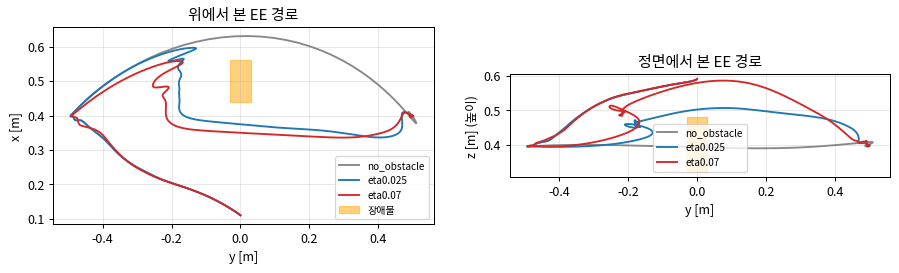

In [9]:
from matplotlib.patches import Rectangle
LC = {'no_obstacle': '#888888', 'eta0.025': '#1f77b4', 'eta0.07': '#d62728'}
ob = RUNS['eta0.025']['settings']['obstacle']
(x, y, z), (dx, dy, dz) = ob['pose'][:3], ob['dims']

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, r in RUNS.items():
    ax[0].plot(r['ee'][:, 1], r['ee'][:, 0], color=LC[n], label=n)
    ax[1].plot(r['ee'][:, 1], r['ee'][:, 2], color=LC[n], label=n)
ax[0].add_patch(Rectangle((y - dy / 2, x - dx / 2), dy, dx, color='orange', alpha=0.5, label='장애물'))
ax[1].add_patch(Rectangle((y - dy / 2, z - dz / 2), dy, dz, color='orange', alpha=0.5))
ax[0].set(xlabel='y [m]', ylabel='x [m]', title='위에서 본 EE 경로')
ax[1].set(xlabel='y [m]', ylabel='z [m] (높이)', title='정면에서 본 EE 경로')
for a in ax:
    a.set_aspect('equal'); a.legend(fontsize=8)
plt.show()

eta0.025: B로 접근하는 동안(목표까지 0.3 m 이상) 이격의 중앙값 25.9 mm, B 구간 EE 최고 높이 0.51 m
eta0.07: B로 접근하는 동안(목표까지 0.3 m 이상) 이격의 중앙값 69.1 mm, B 구간 EE 최고 높이 0.59 m


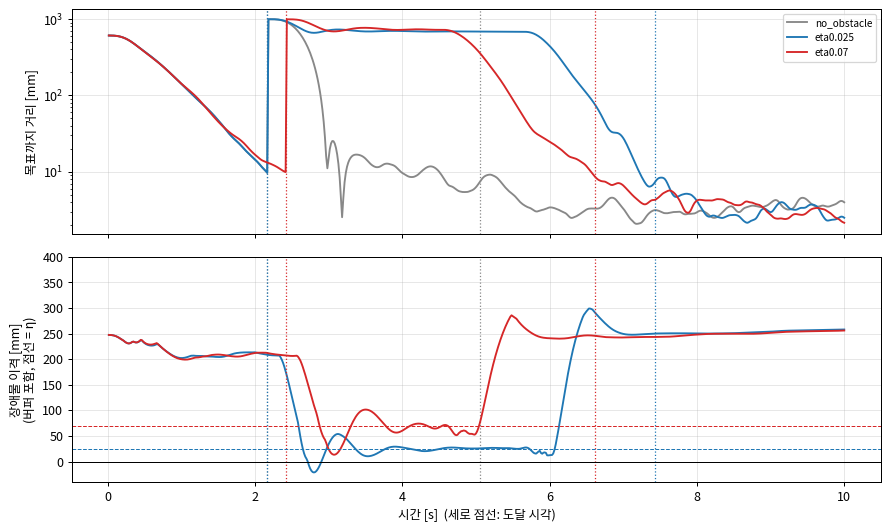

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for n, r in RUNS.items():
    ax[0].plot(r['t'], r['err'] * 1000, color=LC[n], label=n)
    ax[1].plot(r['t'], r['clr'] * 1000, color=LC[n], label=n)
    for ts in r['arrive'].values():
        for a in ax:
            a.axvline(ts, color=LC[n], ls=':', lw=1)
ax[0].set(ylabel='목표까지 거리 [mm]', yscale='log'); ax[0].legend(fontsize=8)
ax[1].axhline(0, color='k', lw=0.8)
for eta, n in [(25, 'eta0.025'), (70, 'eta0.07')]:
    ax[1].axhline(eta, color=LC[n], ls='--', lw=0.8)
ax[1].set(ylabel='장애물 이격 [mm]\n(버퍼 포함, 점선 = η)', xlabel='시간 [s]  (세로 점선: 도달 시각)', ylim=(-40, 400))
plt.tight_layout(); plt.show()

for n in ['eta0.025', 'eta0.07']:
    r = RUNS[n]
    near = (r['goal'] == 'B') & (r['err'] > 0.3)
    print(f'{n}: B로 접근하는 동안(목표까지 0.3 m 이상) 이격의 중앙값 {np.nanmedian(r["clr"][near]) * 1000:.1f} mm, '
          f'B 구간 EE 최고 높이 {r["ee"][r["goal"] == "B", 2].max():.2f} m')

**결과 해석** (seed 0, 조건별 1회 실행)

1. **장애물 앞에서 멈칫한다.** 두 η 조건 모두 B로 가다가 목표까지 0.6 m 이상 남은 채 한동안 머문다(η 25 mm에서 약 3.7초, 70 mm에서 약 2.4초). 06 노트의 local minimum과 같은 현상이다. 곧장 가면 충돌 비용이 커지고, 0.675초 horizon 안에서는 크게 돌아가는 이득이 잘 보이지 않는다.
2. **멈칫하는 동안 이격이 η 근처에 머문다.** 접근 중 이격 중앙값이 η 25 mm에서 약 26 mm, η 70 mm에서 약 69 mm다. 간격이 η 이상이면 충돌 비용이 0이라, 목표 비용에 끌려 η 경계까지 다가간 뒤 그 경계를 따라 미끄러지는 모양이다. η가 "유지 거리"처럼 보이는 이유지만 보장은 아니다. η 25 mm에서는 빠져나가는 순간 버퍼 포함 이격이 −21 mm까지 내려갔다.
3. **η를 키웠더니 오히려 A→B가 약 1초 빨라졌다.** η 70 mm는 더 높이 넘어가는 경로(B 구간 EE 최고 높이 0.51 m → 0.59 m)를 골라 멈칫하는 시간이 짧았다. 12 노트에서 말한 "η가 크면 항상 늦다고 일반화하면 안 된다"의 예다.
4. **A 도달 시각도 달라졌다**(2.17 s → 2.42 s). 이 실습의 η는 장애물뿐 아니라 테이블·벽까지 **모든** 환경 장애물에 적용되기 때문이다. 프로젝트의 LOW/HIGH는 손 비용의 η만 바꿔서 A 도달 시각이 같았다(12 노트). 그래서 이 실습 결과를 프로젝트의 LOW → HIGH와 같은 실험으로 보면 안 된다.
5. **모든 스텝이 feasible이었다.** 버퍼 포함 이격이 음수인 순간에도 그렇다. 12 노트의 결론과 같다.

**직접 해보기:** 위 결과를 보고 "η를 0.1 m로 더 키우면 A→B 시간이 더 줄어든다"고 결론 내려도 될까?
<details><summary>답</summary>

안 된다. 실행이 조건별 한 번뿐이고, 시간이 줄어든 이유(우회 경로가 바뀐 것)는 장면에 따라 달라진다. η를 더 키우면 장애물 근처의 넓은 영역이 모두 비싸져서 오히려 더 오래 멈출 수도 있다. 직접 돌려 봐야 안다(9절 실험 1).
</details>

## 9. 직접 해 볼 실험

각 실험은 실행 전에 결과를 먼저 예상해 적어 두고, 실행한 뒤 비교한다. `run_lab('이름', '--인자', 값)` 형태로 7절의 셀에서 실행할 수 있다.

| # | 실험 | 인자 | 먼저 예상해 볼 것 |
|---|---|---|---|
| 1 | η 바꾸기 | `--eta 0.01`, `0.05`, `0.1` | 최소 이격과 A→B 시간이 η에 따라 한 방향으로만 변할까? |
| 2 | 충돌 구 여유 | `--buffer 0.004` (cuRobo 기본) | 버퍼 **제외** 이격은 어떻게 변할까? buffer와 η는 무엇이 다를까? |
| 3 | 후보 수 | `--particles 100`, `1000` | 계산 시간과 경로, 멈칫하는 시간은? |
| 4 | 온도 β | `--beta 0.01`, `1.0` | 가중치 집중도가 바뀌면 경로가 매끄러워질까? (05 노트) |
| 5 | 장애물 크기 | `--obstacle 0.5 0 0.4 0.12 0.2 0.3` | 위로 넘어가던 로봇이 옆으로 돌아갈까? |
| 6 | MPC dt | `--step-dt 0.02` | horizon이 0.75 s로 길어지면 멈칫하는 시간이 줄어들까? |

<details><summary>힌트: buffer와 η의 차이 (실험 2)</summary>

buffer는 충돌 구 자체를 키운다. 그래서 키운 만큼 겹침 판정과 이격 계산 기준이 함께 바뀐다. η는 구 크기는 그대로 두고, 비용이 0이 아니게 되는 거리만 넓힌다. 둘 다 "더 일찍 피하게" 만들지만, buffer는 로그의 버퍼 포함 이격 기준까지 바꾼다는 점이 다르다.
</details>

<details><summary>힌트: horizon 길이 (실험 6)</summary>

06 노트에서 horizon이 길면 우회 이득이 비용에 드러나 local minimum이 줄 수 있다고 배웠다. 다만 MPC dt가 물리 dt(1/60 s)와 어긋나므로 모델 예측과 실제 진행이 조금 맞지 않게 된다. 두 효과 중 어느 쪽이 큰지는 실행해 봐야 안다.
</details>

## 10. 노트북에서 Isaac Sim을 직접 띄우지 않는 이유

이 노트는 Isaac Sim을 `subprocess`로 따로 실행했다. 노트북 커널 안에서 `SimulationApp`을 직접 만들 수도 있지만 제약이 많다.
- 커널 하나에서 `SimulationApp`은 **한 번만** 만들 수 있다. 닫은 뒤 다시 만들려면 커널을 재시작해야 한다.
- 화면을 갱신하려면 `world.step(render=True)`를 계속 불러야 해서, 그동안 다른 셀을 실행할 수 없다.
- CUDA graph를 녹화한 solver가 커널이 살아 있는 동안 GPU 메모리를 계속 잡는다.

그래서 반복 실험은 "스크립트로 실행 → 결과 파일 저장 → 노트북에서 분석" 방식이 다루기 쉽다. 프로젝트의 `hand_experiment.py`도 같은 방식이다. 이 노트북은 "Isaac Sim 4.5 + cuRobo" 커널에서 열고, 분석 셀은 Isaac Sim 없이도 실행된다.

## 핵심 정리

- Isaac Sim은 01 노트의 "실제 카트" 역할이다. cuRobo가 질량 없는 모델로 계획하고, Isaac Sim이 물리대로 움직이고, MPC가 매 스텝 측정값으로 보정한다.
- 관절 드라이브는 위치 명령을 용수철·댐퍼(PD)처럼 따라가므로 항상 조금 늦다.
- 시간은 세 가지다. 물리 dt(1/60 s), MPC dt(1/60 s로 맞춤), horizon(0.675 s).
- Isaac Sim 스크립트는 `SimulationApp`을 먼저 만들고 그 뒤에 Isaac 모듈을 import한다. 화면의 상자와 cuRobo의 충돌 세계는 따로 만든다.
- 실습에서 η를 키우면 이격이 커졌지만 시간은 오히려 줄었다. 장애물 앞 멈칫(local minimum)과 "η 경계를 따라 미끄러지는" 모습이 보인다. 단일 실행이라 일반화할 수 없다.

## 확인 문제

<details><summary>1. 스크립트에서 `from isaacsim.core.api import World`를 `SimulationApp(...)`보다 먼저 쓰면 어떻게 되나? 왜?</summary>

import가 실패한다. 이 모듈은 Isaac Sim의 Kit 프로그램이 확장들을 불러온 뒤에야 쓸 수 있는데, `SimulationApp`이 그 Kit를 시작하는 역할이기 때문이다.
</details>

<details><summary>2. 04 노트의 MPC 루프에서 "실제 시스템이 한 스텝 진행"에 해당하는 줄과, "첫 입력만 실행"에 해당하는 줄은?</summary>

`world.step()`이 실제 시스템의 한 스텝이고, `controller.apply_action(cmd.position)`이 첫 입력(첫 위치 명령) 실행이다.
</details>

<details><summary>3. η 25 mm 실행에서 이격이 25 mm 근처에 오래 머문 이유를 비용 함수로 설명하면?</summary>

충돌 비용은 간격이 η 이상이면 0이고, η 안쪽에서만 커진다. 목표 비용은 장애물 쪽으로 당기고 충돌 비용은 η 안쪽에서 밀어내므로, 둘이 맞서는 η 경계 근처에서 로봇이 머물며 경계를 따라 움직인다.
</details>

<details><summary>4. 이 실습의 η 변경이 프로젝트의 LOW → HIGH와 다른 점은? 그 차이가 결과의 어디에서 드러났나?</summary>

이 실습은 테이블·벽·장애물 전체의 환경 비용 η를 바꿨고, 프로젝트는 손 전용 비용의 η만 바꿨다. 그래서 이 실습에서는 장애물과 먼 A 구간에서도 결과가 달라져 A 도달 시각이 2.17 s에서 2.42 s로 바뀌었다. 프로젝트는 세 조건의 A 도달 시각이 같았다.
</details>

<details><summary>5. PD 드라이브의 kp를 크게 하면 MPC가 측정 상태를 다시 넣을 필요가 없어지나?</summary>

아니다. 지연은 줄지만 0이 되지 않는다. 모델에 없는 질량·관성·접촉도 있다. 매 스텝 측정값을 다시 넣는 것이 MPC가 모델 오차를 보정하는 방법이다.
</details>

## 실제 프로젝트에서는

| 이 노트 (`scripts/mpc_lab.py`) | 프로젝트 (`experiment/hand_experiment.py`) |
|---|---|
| `SimulationApp` 생성 41줄 → Isaac import 43줄~ | 63줄 생성 → 64줄부터 import |
| 장애물: 상자 하나 (`PRIMITIVE`) | 깊이 지도(nvblox, `BLOX`) + 손 패치 비용 |
| η: 환경 전체 (`collision_activation_distance`) | 손 패치 비용의 η만 (`--eta-exponent`, 104-111줄) |
| 측정 상태 입력 → `mpc.step` → 위치 명령 | 278-317줄, 같은 구조 (`--state-input measured`) |
| 도달 판정 10 mm · 0.05 rad | 287-296줄, `goal_progress.py` |
| 결과: `scripts/results/*.jsonl` | `evidence/{R,LOW,HIGH}/metrics.jsonl` 등 |

## 마무리

01 노트의 카트 한 대에서 시작해 여기까지 왔다. 지금까지 배운 것을 한 줄로 이으면 다음과 같다.

**상태와 모델로 미래를 예측하고(01) → 비용으로 점수를 매기고(02) → 가장 좋은 입력을 찾되(03) → 첫 입력만 실행하고 다시 계획한다(04). 그 "찾기"를 샘플과 softmax 가중치로 하는 것이 MPPI이고(05~07), 로봇팔에서는 충돌 구와 η 비용으로 장애물을 피한다(08~09). 깊이 카메라 지도와 손 전용 비용을 더한 것이 이 프로젝트이고(10~11), 그 결과는 공정한 비교와 정확한 거리 기준으로 읽어야 한다(12). 마지막으로 물리 시뮬레이터에서 직접 돌려 보며 모델과 실제의 차이를 확인했다(13).**

더 나아가려면 9절의 실험을 직접 돌려 보거나, [00 · 시작하기](00_start_here.ipynb)의 지도를 다시 보며 궁금한 노트로 돌아가 보자.